## Classification Example – k-Nearest Neighbors (kNN)

In [1]:
import pandas as pd
import numpy as np
from scipy.stats import shapiro
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score,precision_score,recall_score,f1_score

#1. Loading data

In [4]:
# Loading the dataset and specifing the values treated as missing
df = pd.read_csv("spotify.csv", na_values=['-', ' ', ''], encoding='latin1')

display(df.head())
df.info()

,track_name,released_year,in_spotify_playlists,in_spotify_charts,streams,in_apple_playlists,in_apple_charts,bpm,mode,energy,instrumentalness,liveness,speechiness
0,Seven (feat. Latto) (Explicit Ver.),2023,553,147.0,141381703,43,263.0,125,Major,83,0,8,4
1,LALA,2023,1474,48.0,133716286,48,126.0,92,Major,74,0,10,4
2,vampire,2023,1397,113.0,140003974,94,207.0,138,Major,53,0,31,6
3,Cruel Summer,2019,7858,NaN,800840817,116,207.0,170,Major,72,0,11,15
4,WHERE SHE GOES,2023,3133,50.0,303236322,84,133.0,144,Minor,80,63,11,6


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 953 entries, 0 to 952
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   track_name            953 non-null    object 
 1   released_year         953 non-null    int64  
 2   in_spotify_playlists  953 non-null    int64  
 3   in_spotify_charts     951 non-null    float64
 4   streams               953 non-null    int64  
 5   in_apple_playlists    953 non-null    int64  
 6   in_apple_charts       951 non-null    float64
 7   bpm                   953 non-null    int64  
 8   mode                  953 non-null    object 
 9   energy                953 non-null    int64  
 10  instrumentalness      953 non-null    int64  
 11  liveness              953 non-null    int64  
 12  speechiness           953 non-null    int64  
dtypes: float64(2), int64(9), object(2)
memory usage: 96.9+ KB


#2. Creating the Target Variable

In [6]:
# Checking for missing values in `streams` before using it to create the target
print("Number of missing values in streams:", df['streams'].isna().sum())
# No missing values were found

# Calculating the third quartile
streams_3Q = df['streams'].quantile(0.75)
print('3rd quantile :',streams_3Q)

# Creating the binary target `HighStreams` from `streams`
df['HighStreams'] = np.where(df['streams'] > streams_3Q, 'Yes', 'No')
df['HighStreams'] = df['HighStreams'].map({'Yes': 1, 'No': 0})

# Removing `streams` to prevent target leakage
df.drop(columns='streams', inplace=True)

Number of missing values in streams: 0
3rd quantile : 673801126.0


#3. Handling Missing Values

In [7]:
# Checking the number of missing values in each column
print(df.isna().sum())
# `in_spotify_charts` and `in_apple_charts` each contain two missing values

track_name              0
released_year           0
in_spotify_playlists    0
in_spotify_charts       2
in_apple_playlists      0
in_apple_charts         2
bpm                     0
mode                    0
energy                  0
instrumentalness        0
liveness                0
speechiness             0
HighStreams             0
dtype: int64


#4. Inspecting distributions of the columns with missing values
The numerical variables `in_spotify_charts` and `in_apple_charts` contain only a small number of missing values. We will therefore consider mean or median imputation. To choose between them, we first examine the distributions using the Shapiro–Wilk test. If a variable is approximately normally distributed, we will use its mean; otherwise, we will use its median.

In [8]:
# Checking whether the variables follow a normal distribution
p_spotify = shapiro(df['in_spotify_charts'].dropna())[1]
p_apple = shapiro(df['in_apple_charts'].dropna())[1]

print("p-value for in_spotify_charts:", p_spotify)
print("p-value for in_apple_charts:", p_apple)
# Both p-values are below 0.05, so median imputation is used

median_spotify = df['in_spotify_charts'].median()
print(median_spotify)
median_apple = df['in_apple_charts'].median()
print(median_apple)
# The median values are 3 for Spotify and 38 for Apple, respectively

# Replacing missing values with the corresponding medians
df['in_spotify_charts'] = df['in_spotify_charts'].fillna(median_spotify)
df['in_apple_charts'] = df['in_apple_charts'].fillna(median_apple)

print(df.isna().sum())
# No missing values remain

p-value for in_spotify_charts: 1.4519411043897098e-39
p-value for in_apple_charts: 4.467185022285124e-26
3.0
38.0
track_name              0
released_year           0
in_spotify_playlists    0
in_spotify_charts       0
in_apple_playlists      0
in_apple_charts         0
bpm                     0
mode                    0
energy                  0
instrumentalness        0
liveness                0
speechiness             0
HighStreams             0
dtype: int64


#5. Assessing Feature Relevance for the Model

In [9]:
# Removing column `track_name` because it is an identifier rather than a useful predictive feature
# Each song has a distinct name, which is unlikely to generalize to unseen songs
df.drop(columns='track_name', inplace=True)

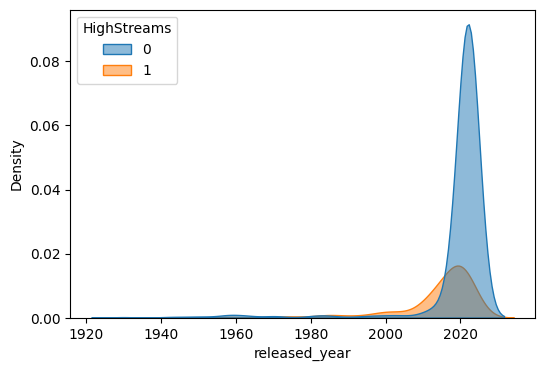

In [10]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='released_year', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

# The distributions of `released_year` differ between the two target classes, suggesting that this feature may be useful

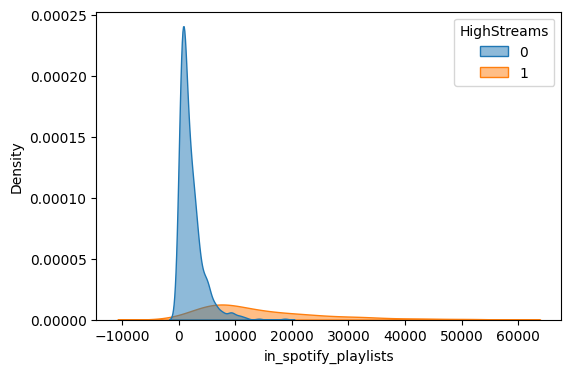

In [11]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='in_spotify_playlists', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

# Songs appearing in more Spotify playlists tend to have more streams, so this feature may be informative

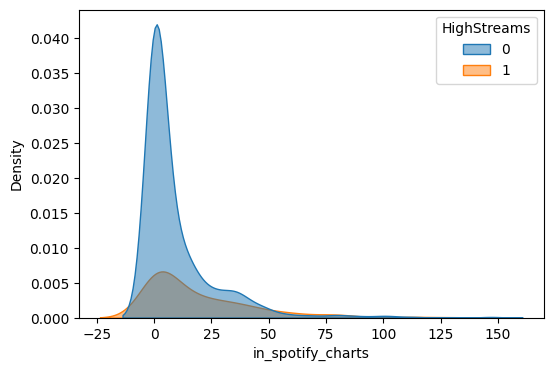

In [12]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='in_spotify_charts', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

# The distribution of `in_spotify_charts` differs between the target classes, so this feature may be useful for prediction

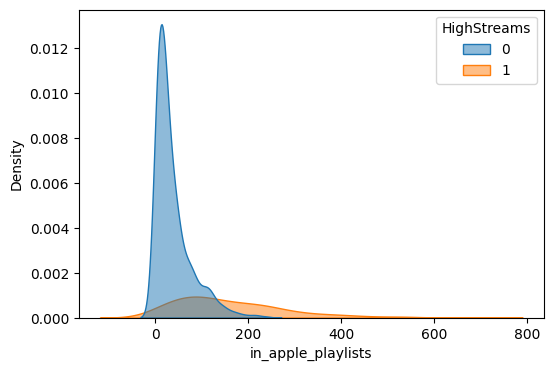

In [13]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='in_apple_playlists', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

# Songs appearing in more Apple playlists tend to have more streams, so this feature may be informative

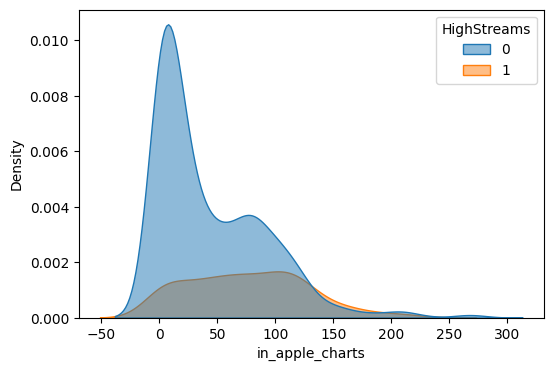

In [14]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='in_apple_charts', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

# The distribution of `in_apple_charts` differs between the target classes, so this feature may be useful for prediction

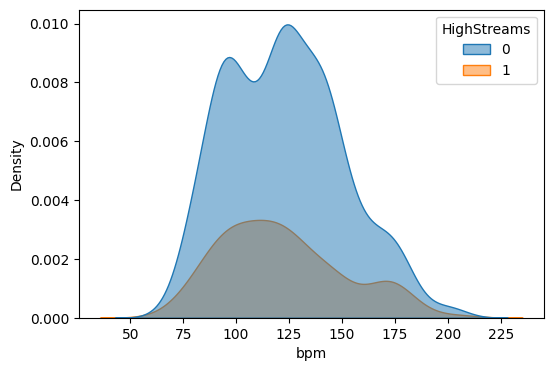

In [15]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='bpm', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

# The `bpm` distributions appear similar across the two target classes; this feature is excluded
df.drop(columns='bpm', inplace=True)

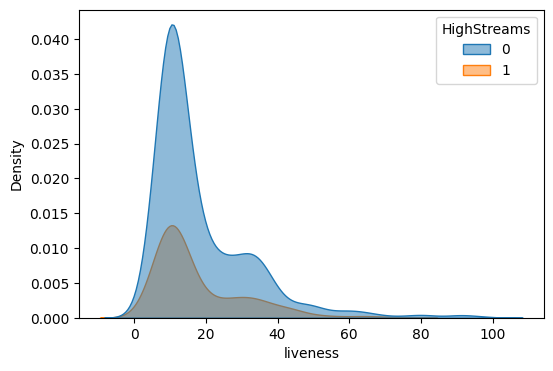

In [16]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='liveness', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

# The `liveness` distributions appear similar across the two target classes; this feature is excluded
df.drop(columns='liveness', inplace=True)

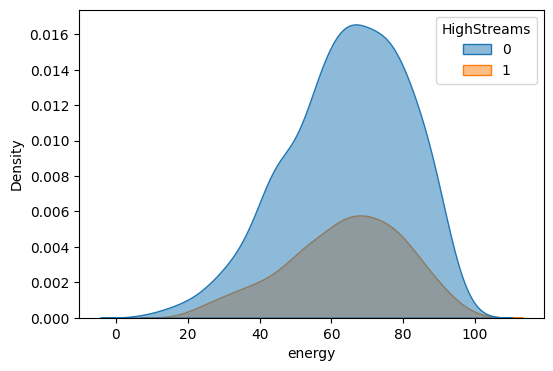

In [17]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='energy', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

# The `energy` distributions appear similar across the two target classes; this feature is excluded
df.drop(columns='energy', inplace=True)

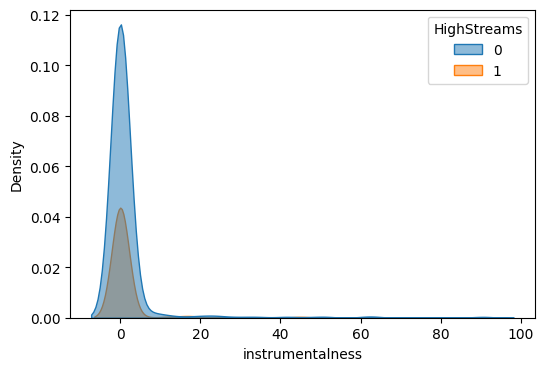

In [18]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='instrumentalness', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

# The `instrumentalness` distributions appear similar across the two target classes; this feature is excluded
df.drop(columns='instrumentalness', inplace=True)

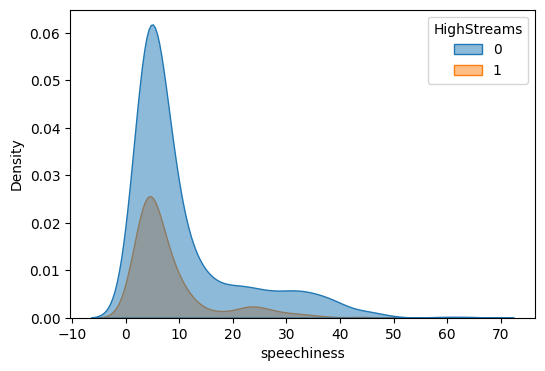

In [19]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='speechiness', hue='HighStreams', fill=True, alpha=0.5)
plt.show()

# The `speechiness` distributions appear similar across the two target classes; this feature is excluded
df.drop(columns='speechiness', inplace=True)

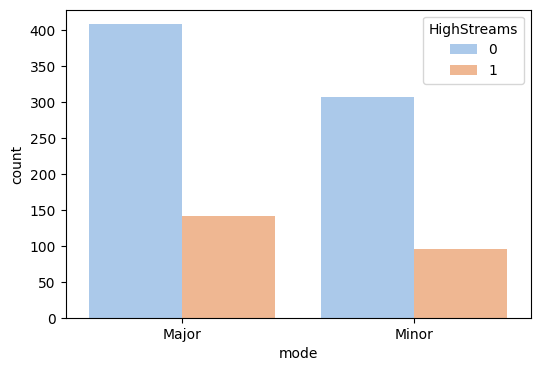

In [20]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='mode', hue='HighStreams', palette='pastel')
plt.show()

# Songs in minor mode appear slightly more likely to have fewer streams; we retain this feature as a possible predictor

#6. Scaling Numerical Features

In [21]:
print(df.describe())
print(df.info())

       released_year  in_spotify_playlists  in_spotify_charts  \
count     953.000000            953.000000         953.000000   
mean     2018.238195           5200.124869          11.853095   
std        11.116218           7897.608990          19.320751   
min      1930.000000             31.000000           0.000000   
25%      2020.000000            875.000000           0.000000   
50%      2022.000000           2224.000000           3.000000   
75%      2022.000000           5542.000000          16.000000   
max      2023.000000          52898.000000         147.000000   

       in_apple_playlists  in_apple_charts  HighStreams  
count          953.000000       953.000000   953.000000  
mean            67.812172        51.665268     0.249738  
std             86.441493        50.376630     0.433088  
min              0.000000         0.000000     0.000000  
25%             13.000000         7.000000     0.000000  
50%             34.000000        38.000000     0.000000  
75%     

In [22]:
numeric_vars = ['released_year', 'in_spotify_playlists', 'in_spotify_charts', 'in_apple_playlists', 'in_apple_charts']

We're checking the numerical variables for outliers before choosing a scaling method. Because the variables contain outliers, we will use `RobustScaler`, which scales values using the median and interquartile range (IQR).

In [23]:
# Function for counting outliers using the IQR rule
def count_outliers(variable):
    q1 = variable.quantile(0.25)
    q3 = variable.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return ((variable < lower) | (variable > upper)).sum()

outliers_per_column = df[numeric_vars].apply(count_outliers)
print("Number of outliers by column:\n", outliers_per_column)
# All selected numerical features contain outliers, so robust scaling is appropriate

Number of outliers by column:
 released_year           151
in_spotify_playlists    109
in_spotify_charts        76
in_apple_playlists       78
in_apple_charts          12
dtype: int64


In [24]:
# Checking the distributions using the Shapiro–Wilk test
shapiro_results = df[numeric_vars].apply(lambda x: shapiro(x)[1])
print("Shapiro–Wilk p-values:\n", shapiro_results)

# All p-values are below 0.05, indicating departures from normality
# We use `RobustScaler`, which relies on the median and IQR

Shapiro–Wilk p-values:
 released_year           1.210310e-47
in_spotify_playlists    2.585440e-41
in_spotify_charts       1.284461e-39
in_apple_playlists      4.262281e-37
in_apple_charts         4.332586e-26
dtype: float64


In [25]:
# Scaling numerical features using RobustScaler
robust_scaler = RobustScaler()
df_st = pd.DataFrame() # Creating an empty DataFrame for the prepared kNN features
df_st[numeric_vars] = robust_scaler.fit_transform(df[numeric_vars])

#7. Encoding Binary and Categorical Features

In [26]:
print(df.info())
# The only non-numeric feature is `mode`

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 953 entries, 0 to 952
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   released_year         953 non-null    int64  
 1   in_spotify_playlists  953 non-null    int64  
 2   in_spotify_charts     953 non-null    float64
 3   in_apple_playlists    953 non-null    int64  
 4   in_apple_charts       953 non-null    float64
 5   mode                  953 non-null    object 
 6   HighStreams           953 non-null    int64  
dtypes: float64(2), int64(4), object(1)
memory usage: 52.2+ KB
None


In [27]:
print(df['mode'].unique())
# `mode` has two categories (`Major` and `Minor`), so it can be encoded as 0 and 1
df_st['mode'] = df['mode'].map({'Major': 0, 'Minor': 1})

['Major' 'Minor']


In [28]:
# Adding the target variable `HighStreams` to the prepared DataFrame
df_st['HighStreams'] = df['HighStreams']

#8. Splitting the Data into Training and Test Sets

In [29]:
# Splitting the dataset into training (80%) and test (20%) sets

X = df_st.drop(columns='HighStreams')
y = df_st['HighStreams']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

#9. Finding the Optimal Value of `k`

In [30]:
knn = KNeighborsClassifier()

# Searching odd values of k from 3 to 25 to reduce the chance of ties
param_grid = {'n_neighbors': list(range(3, 26, 2))}

# Using 10-fold cross-validation
cv = GridSearchCV(estimator=knn,
                  param_grid=param_grid,
                  cv=10,
                  scoring='accuracy',
                  verbose = 1,
                  n_jobs = -1)
cv.fit(X_train, y_train)

best_k = cv.best_params_['n_neighbors']
print("Optimal value of k:", best_k)
# The optimal number of neighbors is k = 11

Fitting 10 folds for each of 12 candidates, totalling 120 fits
Optimal value of k: 11


#10. Training the kNN Classifier with the Selected `k`

In [31]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=11)

In [32]:
y_pred = knn.predict(X_test)

#11. Evaluating Confusion Matrix

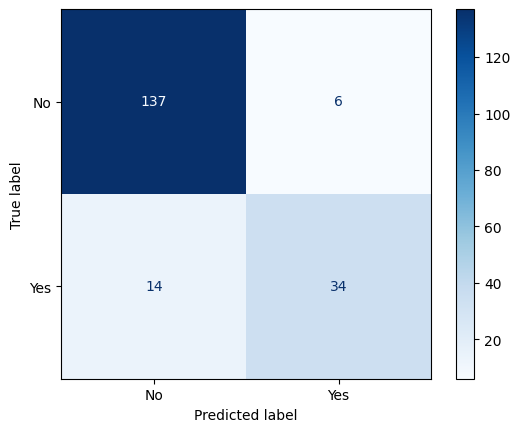

In [33]:
cm_knn = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_knn,
                              display_labels=['No', 'Yes'])
disp.plot(cmap=plt.cm.Blues)
plt.show()

#### Confusion Matrix Interpretation

- **True positive (TP):** 34 songs were correctly predicted to have a high number of streams.
- **True negative (TN):** 137 songs were correctly predicted not to have a high number of streams.
- **False positive (FP):** 6 songs were predicted to have a high number of streams, but actually did not.
- **False negative (FN):** 14 songs were predicted not to have a high number of streams, but actually did.

The main diagonal (137 and 34) contains correct predictions, while the off-diagonal entries (6 and 14) represent misclassifications.

#12. Evaluation Metrics

The four most commonly used classification metrics are:

- **Accuracy:** The proportion of all observations classified correctly.
- **Precision:** The proportion of predicted positive observations that are actually positive.
- **Recall:** The proportion of actual positive observations correctly identified by the classifier.
- **F1-score:** The harmonic mean of precision and recall, balancing the two metrics.

In [34]:
def compute_eval_metrics(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, pos_label=1)
    recall = recall_score(y_true, y_pred, pos_label=1)
    f1 = f1_score(y_true, y_pred, pos_label=1)
    return {
        'accuracy': accuracy,
        'precision': float(precision),
        'recall': float(recall),
        'f1': float(f1)
    }

In [35]:
knn_eval = compute_eval_metrics(y_test, y_pred)
print(knn_eval)

{'accuracy': 0.8952879581151832, 'precision': 0.85, 'recall': 0.7083333333333334, 'f1': 0.7727272727272727}


### Interpretation of Evaluation Metrics

- **Accuracy:** The model correctly predicts whether a song has a high number of streams in **89.53%** of cases.
- **Precision:** Of the songs predicted to have a high number of streams, **85%** actually do.
- **Recall:** Of all songs that actually have a high number of streams, the model correctly identifies **70.83%**.
- **F1-score:** The F1-score is approximately **0.77**, reflecting the balance between identifying high-stream songs and limiting false positive predictions.

**Note:** These interpretations are examples of how the assignment requirements can be addressed.